Integral de sin(x) entre 0 y pi
Valor exacto: 2.0
------------------------------------------------------------------------
n= 2 | T=1.5707963268 | error T=4.292e-01 | S=2.0943951024 | error S=9.440e-02
n= 4 | T=1.8961188979 | error T=1.039e-01 | S=2.0045597550 | error S=4.560e-03
n= 8 | T=1.9742316019 | error T=2.577e-02 | S=2.0002691699 | error S=2.692e-04
n=16 | T=1.9935703438 | error T=6.430e-03 | S=2.0000165910 | error S=1.659e-05
n=32 | T=1.9983933610 | error T=1.607e-03 | S=2.0000010334 | error S=1.033e-06


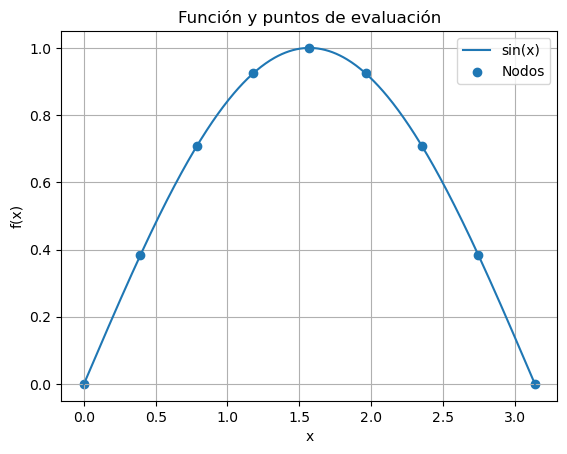

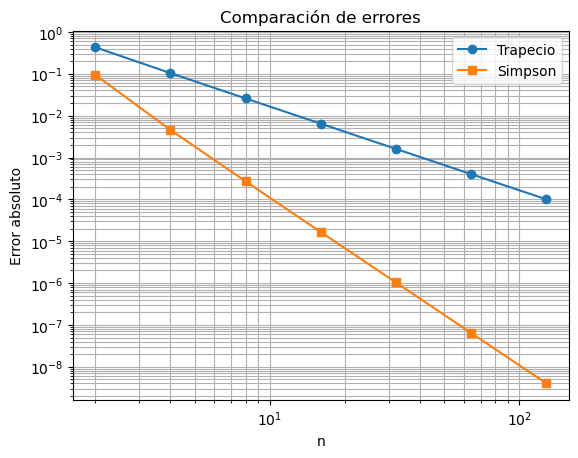

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def trapecio(f, a, b, n):
    """Regla del trapecio compuesta, malla uniforme."""
    if n < 1:
        raise ValueError("n debe ser positivo.")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return h / 2 * (y[0] + 2*np.sum(y[1:-1]) + y[-1])

def simpson(f, a, b, n):
    """Simpson 1/3 compuesto. n debe ser par."""
    if n < 2 or n % 2 != 0:
        raise ValueError("Para Simpson 1/3, n debe ser par.")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return h / 3 * (
        y[0] + y[-1]
        + 4*np.sum(y[1:-1:2])
        + 2*np.sum(y[2:-2:2])
    )

def simpson_38(f, a, b, n):
    """Simpson 3/8 compuesto. n debe ser múltiplo de 3."""
    if n < 3 or n % 3 != 0:
        raise ValueError("Para Simpson 3/8, n debe ser múltiplo de 3.")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    idx = np.arange(1, n)
    s3 = np.sum(y[idx[idx % 3 != 0]])
    s2 = np.sum(y[idx[idx % 3 == 0]])
    return 3*h/8 * (y[0] + y[-1] + 3*s3 + 2*s2)

def error_absoluto(valor, referencia):
    return abs(valor - referencia)

def comparar(f, exacta, a, b, ns):
    filas = []
    for n in ns:
        T = trapecio(f, a, b, n)
        S = simpson(f, a, b, n) if n % 2 == 0 else np.nan
        filas.append((n, T, abs(T-exacta), S,
                      abs(S-exacta) if np.isfinite(S) else np.nan))
    return filas

if __name__ == "__main__":
    f = np.sin
    a, b = 0.0, np.pi
    exacta = 2.0

    print("Integral de sin(x) entre 0 y pi")
    print("Valor exacto:", exacta)
    print("-"*72)
    for n in [2, 4, 8, 16, 32]:
        T = trapecio(f, a, b, n)
        S = simpson(f, a, b, n)
        print(f"n={n:2d} | T={T:.10f} | "
              f"error T={abs(T-exacta):.3e} | "
              f"S={S:.10f} | error S={abs(S-exacta):.3e}")

    # Visualización de la función y los nodos.
    x = np.linspace(a, b, 9)
    plt.figure()
    xx = np.linspace(a, b, 500)
    plt.plot(xx, f(xx), label="sin(x)")
    plt.scatter(x, f(x), label="Nodos")
    plt.xlabel("x"); plt.ylabel("f(x)")
    plt.title("Función y puntos de evaluación")
    plt.legend(); plt.grid(True); plt.show()

    # Comparación de errores en escala log-log.
    ns = np.array([2, 4, 8, 16, 32, 64, 128])
    res = comparar(f, exacta, a, b, ns)
    eT = np.array([r[2] for r in res])
    eS = np.array([r[4] for r in res])
    plt.figure()
    plt.loglog(ns, eT, "o-", label="Trapecio")
    plt.loglog(ns, eS, "s-", label="Simpson")
    plt.xlabel("n"); plt.ylabel("Error absoluto")
    plt.title("Comparación de errores")
    plt.legend(); plt.grid(True, which="both"); plt.show()